# 02. BLUP со связями и маркерной панелью


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт собирает матрицу H: связи для всех изделий и маркерная панель для части из них (ssGBLUP).

| | |
|---|---|
| **Данные** | `data/lineage.csv`, `data/measurements.csv`, `data/markers.csv` |
| **Цель** | Построить A, G и H и получить оценку через `mixed.solve` |
| **Результат** | Оценка с учётом панели; сравнение с истинным `true_value` |


In [2]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



In [3]:
z_score_filter <- function(pipeline, threshold) {
  z <- abs((pipeline$trait - mean(pipeline$trait, na.rm = TRUE)) / sd(pipeline$trait, na.rm = TRUE))
  pipeline %>% filter(!(z > threshold))
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  out <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(out) <- rownames(matrix)
  colnames(out) <- colnames(matrix)
  out
}

scale_g_to_a <- function(A_matrix, G_matrix) {
  common <- intersect(rownames(G_matrix), rownames(A_matrix))
  G_matrix <- G_matrix[common, common, drop = FALSE]
  A22 <- A_matrix[common, common, drop = FALSE]
  G_matrix * (sum(diag(A22)) / sum(diag(G_matrix)))
}

prepare_ids <- function(lineage, measurements, markers = NULL) {
  ids <- unique(c(measurements$item_id, lineage$item_id, lineage$parent_a, lineage$parent_b))
  if (!is.null(markers)) ids <- unique(c(ids, markers$item_id))
  ids <- ids[ids != 0]
  levels <- as.character(sort(unique(ids)))
  recode <- function(x) as.integer(factor(as.character(x), levels = levels))
  lineage <- lineage %>%
    mutate(
      item_id = recode(item_id),
      parent_a = ifelse(parent_a == 0, 0L, recode(parent_a)),
      parent_b = ifelse(parent_b == 0, 0L, recode(parent_b))
    )
  measurements <- measurements %>% mutate(item_id = recode(item_id))
  if (!is.null(markers)) {
    markers <- markers %>% mutate(item_id = recode(item_id))
  }
  list(lineage = lineage, measurements = measurements, markers = markers, levels = levels)
}

order_lineage <- function(lineage, keep_ids) {
  ped <- editPed(label = lineage$item_id, sire = lineage$parent_a, dam = lineage$parent_b)
  ped <- ped[, c("label", "sire", "dam")]
  names(ped) <- c("item_id", "parent_a", "parent_b")
  ped <- ped %>% filter(item_id %in% keep_ids)
  ped$parent_a[!(ped$parent_a %in% ped$item_id)] <- 0
  ped$parent_b[!(ped$parent_b %in% ped$item_id)] <- 0
  rownames(ped) <- ped$item_id
  ped
}


In [4]:
measurements <- read.csv("data/measurements.csv") %>%
  dplyr::select(item_id, batch_mass, batch_no, line_age, event_season, event_year, trait)
markers <- read.csv("data/markers.csv", colClasses = c(item_id = "character", panel = "character"))
lineage <- read.csv("data/lineage.csv")
reference <- read.csv("data/reference.csv")
head(markers %>% mutate(panel = str_trunc(panel, 24)))


  item_id                    panel
1     121 001002002022000011010...
2     122 001000101010200000100...
3     123 020011011110001011010...
4     124 111011100101100010000...
5     125 111222100001101110000...
6     126 011101201211000010110...


# 1. Подготовка


In [5]:
measurements <- z_score_filter(measurements, 2) %>% drop_na()
lineage <- lineage %>%
  filter(item_id %in% measurements$item_id | parent_a %in% measurements$item_id | parent_b %in% measurements$item_id)
measurements <- measurements %>% filter(item_id %in% lineage$item_id)
markers <- markers %>% filter(item_id %in% as.character(measurements$item_id))
prep <- prepare_ids(lineage, measurements, markers)
lineage_bl <- order_lineage(prep$lineage, prep$measurements$item_id)
meas_bl <- prep$measurements %>%
  mutate(event_season = factor(event_season), event_year = factor(event_year))
mark_bl <- prep$markers


# 2. Матрицы A, G, H


In [6]:
A <- Amatrix(lineage_bl[, c("item_id", "parent_a", "parent_b")], ploidy = 2)
if (nrow(A) == nrow(lineage_bl)) {
  rownames(A) <- as.character(lineage_bl$item_id)
  colnames(A) <- as.character(lineage_bl$item_id)
} else {
  rownames(A) <- as.character(rownames(A))
  colnames(A) <- as.character(colnames(A))
}
meas_bl <- meas_bl[as.character(meas_bl$item_id) %in% rownames(A), ]
meas_bl <- meas_bl[order(match(as.character(meas_bl$item_id), rownames(A))), ]
X <- model.matrix(~ line_age + batch_mass + batch_no + event_season + event_year, data = meas_bl)
Z <- model.matrix(~ 0 + factor(item_id, levels = rownames(A)), data = meas_bl)
colnames(Z) <- rownames(A)

M <- t(sapply(mark_bl$panel, function(x) as.numeric(strsplit(x, "")[[1]])))
rownames(M) <- as.character(mark_bl$item_id)
G <- scale_g_to_a(A, A.mat(as.matrix(M)))
A22 <- A[rownames(G), rownames(G)]
H <- A
H[rownames(G), rownames(G)] <- A22 + (G - A22)
dim(A); dim(G); dim(H)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 1e-04  minutes 


[1] 190 190


[1] 79 79


[1] 190 190


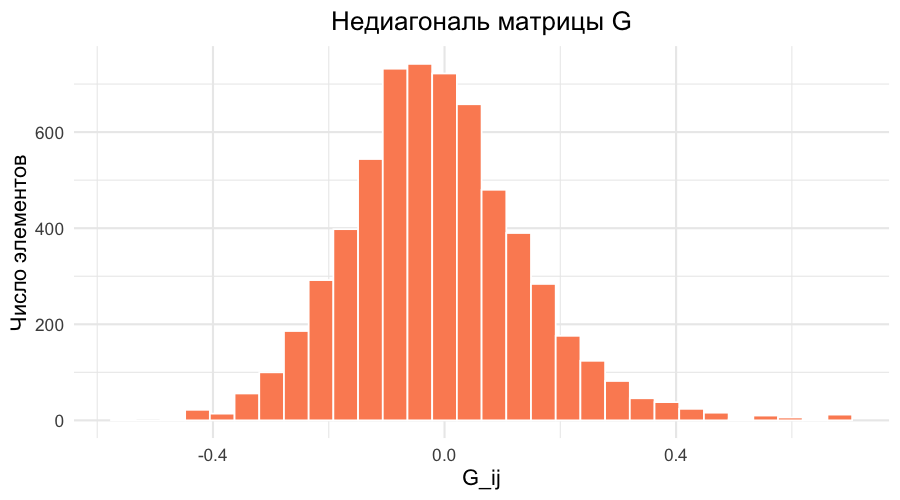

In [7]:
ggplot(data.frame(value = G[row(G) != col(G)]), aes(x = value)) +
  geom_histogram(bins = 30, fill = "#FC8D62", color = "white") +
  labs(title = "Недиагональ матрицы G", x = "G_ij", y = "Число элементов") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 3. Оценка


In [8]:
K_h <- bending((H + t(H)) / 2 + diag(0.2, nrow(H)), 1e-6)
res <- mixed.solve(y = meas_bl$trait, X = X, Z = Z, K = K_h)
est <- res$u
H_inv <- solve(H + diag(0.2, nrow(H)))
se <- sqrt(res$Vu * diag(H_inv))
solutions <- data.frame(
  item_id = as.integer(prep$levels[as.integer(names(est))]),
  estimate = as.numeric(est),
  se = as.numeric(se[names(est)]),
  stringsAsFactors = FALSE
)
solutions$reliability <- 1 - (solutions$se^2 / res$Vu)
cmp <- solutions %>%
  left_join(reference, by = "item_id") %>%
  filter(!is.na(true_value))
cor(cmp$estimate, cmp$true_value)


NaNs produced


[1] 0.4959501


`geom_smooth()` using formula = 'y ~ x'


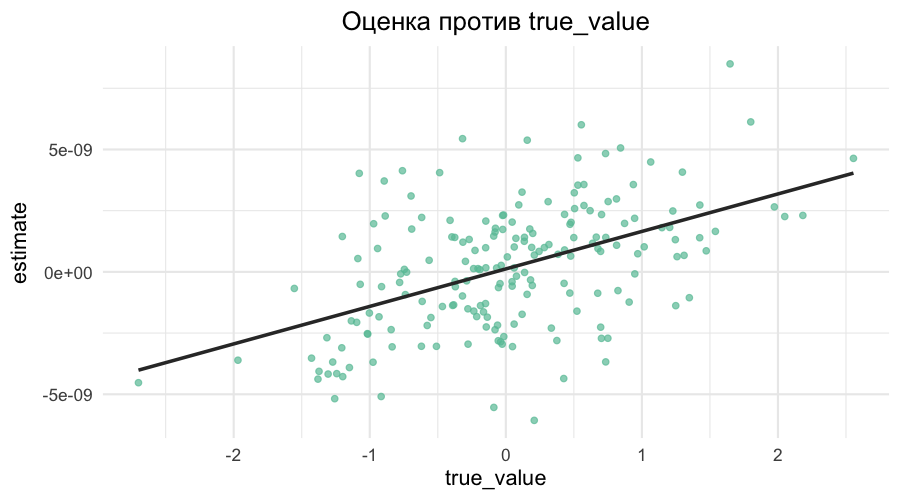

In [9]:
ggplot(cmp, aes(x = true_value, y = estimate)) +
  geom_point(alpha = 0.7, color = "#66C2A5") +
  geom_smooth(method = "lm", se = FALSE, color = "grey20") +
  labs(title = "Оценка против true_value", x = "true_value", y = "estimate") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# Заключение

H подмешивает панель только тем изделиям, у которых она есть, и оставляет связи для остальных. Корреляция с `true_value` показывает, даёт ли панель прирост к одной матрице A.
